<h1>Практическая работа: "Знакомство с алгоритма k-ближайших соседей (kNN)"</h1>

__K-ближайший сосед с использованием scikit-learn__

In [ ]:
!pip install

__Задача обучения__  
Набор данных "Ирисы Фишера". Нужно определить к какому классу принадлежит неопознанное растение ириса,
Классификация осуществляется на основе размеров чашелистиков и лепестков.

In [ ]:
#Импорт необходимых библиотек
import warnings

warnings.filterwarnings('ignore')

In [ ]:
#!pip install mlxtend

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import itertools
from mlxtend.plotting import plot_decision_regions

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, ConfusionMatrixDisplay, confusion_matrix

%matplotlib inline
plt.rcParams["figure.figsize"] = (10,5)

__Изучение набора данных__  
Набор данных "Ирисы Фишера" — это популярный многомерный набор данных, часто используемый в машинном обучении.
Набор данных состоит из 150 образцов, равномерно распределенных по трем видам ирисов:
ирис сетозный, ирис виргинский, ирис разноцветный.
Каждый образец состоит из четырех атрибутов: длины и ширины чашелистиков и лепестков в сантиметрах.
Задача состоит в том, чтобы предсказать, к какому классу принадлежит неопознанное растение ириса,
основываясь на размерах чашелистиков и лепестков.

In [ ]:
dataset = datasets.load_iris()
df = pd.DataFrame(data=np.c_[dataset['data'], dataset['target']],
                    columns=dataset['feature_names'] + ['target'])

df.head()

__Описания наборов данных__

In [ ]:
df.info()

In [ ]:
dict(zip( dataset.target_names, df['target'].unique()))

In [ ]:
temp_df = df.copy()

temp_df['target'] = temp_df['target'].map(dict(zip( temp_df['target'].unique(), dataset.target_names)))

In [ ]:
sns.countplot(x='target', hue='target', data=temp_df)

Из графика выше мы видим, что наши данные идеально сбалансированы.

In [ ]:
sns.pairplot(temp_df, hue='target')

На графике выше мы можем видеть взаимосвязь между каждой функцией. Мы можем увидеть, являются ли признаки разделимыми или нет.

<h2>Синтетический набор данных KNN</h2>

In [ ]:
from IPython.display import display, Javascript, HTML
from IPython.display import IFrame
display(HTML('build.html'))

<h2>Модели КNN</h2>

Теперь мы построим разные модели для разных пар признаков, чтобы увидеть, насколько полезны признаки для определения их вида.

In [ ]:
# Helper functions

def display_confusion_matrix(
    matrix, labels=None,
    title="Confusion Matrix",
    xlabel="Predicted",
    ylabel="Actual",
    figsize=None,
    cmap="Blues",
    vmin=None,
    vmax=None,
):
    """Display a confusion matrix.

    Display the confusion matrix found in matrix using matplotlib.

    Parameters
    ----------
    matrix : array-like
        Confusion matrix to display, shape [n_classes, n_classes].

    labels : array-like, default=None
        Class labels for the confusion matrix, shape [n_classes].

    title : str, default='Confusion Matrix'
        Title displayed on the confusion matrix.

    xlabel : str, default='Predicted'
        x-label displayed on the confusion matrix.

    ylabel : str, default='Actual'
        y-label displayed on the confusion matrix.

    figsize : array-like
        Array-like, length two, specifying the figsize of the plot.

    cmap : matplotib.colors.Colormap or str, default='Blues'
        Colormap used when displaying the entries of the confusion matrix.

    vmin,vmax : int or float
        *vmin* and *vmax* define the data range that the colormap covers.
    """

    if labels is None:
        labels = [""]*len(matrix)
    if vmin is None:
        vmin = 0.
    if vmax is None:
        vmax = np.sum(matrix[0])
    t_hold = (vmax-vmin) / 2.
    fig,ax = plt.subplots(figsize=figsize)
    ax.imshow(matrix, cmap=cmap)
    for row,col in itertools.product(range(len(labels)), range(len(labels))):
        color = "white" if matrix[row,col] > t_hold else "black"
        ax.text(col, row, matrix[row, col], horizontalalignment="center", color=color)
    tick_marks = np.arange(len(labels))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=40, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_yticks(np.arange(len(labels)))
    ax.set_yticklabels(labels)
    plt.show()

<h2>Модель 1 (длина чашелистика и ширина чашелистика)</h2>  
Для начала мы собираемся построить модель KNN с длиной и шириной чашелистика. Мы обучим модель этим двум функциям и оценим ее эффективность с помощью карты классификации и матрицы путаницы.

In [ ]:
X = df[['sepal length (cm)', 'sepal width (cm)']]
y_true = df['target']
model_1 = KNeighborsClassifier()
model_1.fit(X, y_true)

<h3>Оценка модели 1</h3>

In [ ]:
plot_decision_regions(X.values, y_true.values.astype(np.integer), model_1)

In [ ]:
y_hat = model_1.predict(X)
labels = df["target"].unique()

matrix = confusion_matrix(y_true, y_hat, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

<h1>Модель 2 (длина и ширина лепестка)</h1>  
Теперь для нашей второй модели мы собираемся использовать функции длины и ширины лепестка в качестве входных данных.

In [ ]:
X = df[['petal length (cm)', 'petal width (cm)']]

model_2 = KNeighborsClassifier()
model_2.fit(X, y_true)

__Model 2 Evaluation__

In [ ]:
plot_decision_regions(X.values, y_true.values.astype(np.integer), model_2)

In [ ]:
y_hat = model_2.predict(X)

matrix = confusion_matrix(y_true, y_hat, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

<h1>Модель 3 (все функции)</h1>  
Теперь что касается нашей окончательной модели, мы собираемся использовать все доступные функции и обучить нашу модель KNN.

In [ ]:
X = df.drop(['target'], axis=1)

In [ ]:
model_3 = KNeighborsClassifier()
model_3.fit(X, y_true)

__Модель 3 Оценка__

In [ ]:
y_hat = model_3.predict(X)

matrix = confusion_matrix(y_true, y_hat, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

Вы можете видеть, что окончательная модель со всеми функциями работает лучше, чем все другие модели. Меньше ошибочной классификации.

Однако до сих пор мы обучали и оценивали наши модели в одном и том же наборе данных. Использование одних и тех же данных для обучения и оценки не рекомендуется.

__Модель на разделенном наборе данных__

Здесь мы разделим наш набор данных на обучающий и тестовый набор и обучим нашу модель в обучающем наборе. Позже во время оценки мы собираемся использовать наш изолированный набор тестов.

In [ ]:
X = df.drop(['target'], axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3)

In [ ]:
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

In [ ]:
preds = knn.predict(X_test)

print(classification_report(preds, y_test))

In [ ]:
matrix = confusion_matrix(y_test, preds, labels=y.unique(), normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

Выше вы можете видеть, что точность нашего набора тестовых данных составляет 98%.

Из матрицы путаницы мы также видим, что у нас очень низкий уровень ошибок классификации.

Для наших вышеупомянутых моделей мы также можем использовать данные обучения и тестирования отдельно, оценивать эти модели, а затем выбирать лучшую модель.

<h1>Задание</h1>  
С помощью метода kNN определить качество красного вина. Использовать датасет winequality-red.csv, который находится в папке data.
Для этого разделить набор данных на обучающий и тестовый набор и обучим нашу модель в обучающем наборе.
Построить матрицу путаници. Сделать выводы по полученным результатам.

## Идея метода kNN

kNN — метод k ближайших соседей. Для нового образца вина алгоритм:

1. Вычисляет расстояния до обучающих объектов.
2. Находит k ближайших соседей.
3. Подсчитывает, какие оценки качества встречаются среди них.
4. Выбирает оценку с наибольшим числом голосов.

Например, оценки соседей [5, 6, 5, 5, 6] при k = 5 дают прогноз 5.

В этой работе каждый сосед имеет одинаковый вес: weights='uniform'.
Маленькое k делает модель чувствительной к отдельным объектам и шуму.
Большое k сглаживает различия, но может ухудшать распознавание редких классов.

Задача — предсказать quality по 11 физико-химическим признакам.
Столбец quality исключается из входных данных.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import json

from pathlib import Path
from sklearn.model_selection import (
    train_test_split,
    StratifiedGroupKFold,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    mean_absolute_error,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Если у файла другое имя, исправь путь.
df = pd.read_csv("winequality-red.csv")

X = df.drop(columns="quality")
y = df["quality"].astype(int)
classes = np.sort(y.unique())

print("Размер таблицы:", df.shape)
print("Пропуски:", df.isna().sum().sum())
print("Полные повторы:", df.duplicated().sum())
print("\nКоличество объектов каждого класса:")
print(y.value_counts().sort_index())

df.head()

Размер таблицы: (1599, 12)
Пропуски: 0
Полные повторы: 240

Количество объектов каждого класса:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Распределение данных по классам

Посчитаем, сколько образцов вина относится к каждой оценке качества.

На диаграмме горизонтальная ось показывает оценку quality,
вертикальная — количество объектов этого класса.

Неравномерное распределение означает дисбаланс классов. При оценке модели
нужно учитывать, что хорошее распознавание частых оценок может скрывать
ошибки на редких классах.

,Количество,"Доля, %"
Оценка качества,,
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


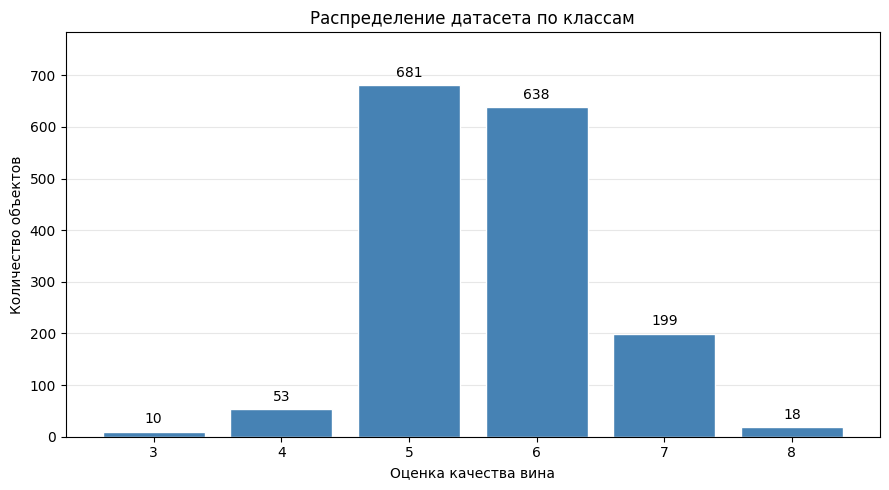

In [ ]:
class_counts = df["quality"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Количество": class_counts,
    "Доля, %": (class_counts / len(df) * 100).round(2)
})
class_distribution.index.name = "Оценка качества"

display(class_distribution)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    class_counts.index.astype(str),
    class_counts.values,
    color="steelblue",
    edgecolor="white"
)

# Подписываем количество объектов над каждым столбцом.
ax.bar_label(bars, padding=4)

ax.set_xlabel("Оценка качества вина")
ax.set_ylabel("Количество объектов")
ax.set_title("Распределение датасета по классам")
ax.set_ylim(0, class_counts.max() * 1.15)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## Проверка дубликатов

Полный дубликат — строка, у которой совпадают значения всех столбцов,
включая quality.

df.duplicated() отмечает повторные вхождения, сохраняя первое неотмеченным.
Поэтому сумма этой маски показывает число повторов сверх первых вхождений.

df.duplicated(keep=False) отмечает все строки повторяющихся групп,
включая первые. Этот вариант удобен для просмотра и сравнения записей.

In [ ]:
# Число повторных строк сверх первых вхождений.
duplicate_count = int(df.duplicated().sum())

# Все строки повторяющихся групп, включая первые вхождения.
duplicate_rows = df.loc[
    df.duplicated(keep=False)
].sort_values(by=df.columns.tolist())

print("Всего строк:", len(df))
print("Повторов сверх первых вхождений:", duplicate_count)
print(f"Доля таких повторов: {duplicate_count / len(df):.2%}")
print("Строк в повторяющихся группах:", len(duplicate_rows))

if duplicate_rows.empty:
    print("Полных дубликатов нет.")
else:
    display(duplicate_rows)

Всего строк: 1599
Повторов сверх первых вхождений: 240
Доля таких повторов: 15.01%
Строк в повторяющихся группах: 460


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
142,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,6
144,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,6
131,5.6,0.500,0.09,2.3,0.049,17.0,99.0,0.99370,3.63,0.63,13.0,5
132,5.6,0.500,0.09,2.3,0.049,17.0,99.0,0.99370,3.63,0.63,13.0,5
1488,5.6,0.540,0.04,1.7,0.049,5.0,13.0,0.99420,3.72,0.58,11.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
391,13.7,0.415,0.68,2.9,0.085,17.0,43.0,1.00140,3.06,0.80,10.0,6
243,15.0,0.210,0.44,2.2,0.075,10.0,24.0,1.00005,3.07,0.84,9.2,7
244,15.0,0.210,0.44,2.2,0.075,10.0,24.0,1.00005,3.07,0.84,9.2,7
554,15.5,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,5


## Разделение данных

Обучающая выборка используется для обучения и подбора k.
Тестовая выборка используется для итоговой проверки после выбора параметра.

В данных присутствуют повторные записи. Чтобы одинаковые примеры не оказались
одновременно в обучении и проверке, объединяем одинаковые наборы признаков
в группы и разделяем группы целиком.

Все исходные строки сохраняются. Из-за разного размера групп тест содержит
приблизительно 30% строк. random_state фиксирует случайное разбиение.

In [ ]:
# Одинаковые наборы признаков получают одинаковый номер группы.
groups = pd.Series(
    pd.factorize(pd.MultiIndex.from_frame(X))[0],
    index=X.index
)

group_info = pd.DataFrame({
    "group": groups,
    "quality": y
})

# В данном файле у одинаковых признаков совпадают оценки качества.
assert group_info.groupby("group")["quality"].nunique().max() == 1

unique_groups = group_info.drop_duplicates("group")

train_groups, test_groups = train_test_split(
    unique_groups["group"],
    test_size=0.2,
    stratify=unique_groups["quality"],
    random_state=13
)

train_mask = groups.isin(train_groups)

X_train = X.loc[train_mask].copy()
X_test = X.loc[~train_mask].copy()
y_train = y.loc[train_mask].copy()
y_test = y.loc[~train_mask].copy()
groups_train = groups.loc[train_mask]

assert set(groups_train).isdisjoint(set(groups.loc[~train_mask]))

print("Обучающих объектов:", len(X_train))
print("Тестовых объектов:", len(X_test))

Обучающих объектов: 1280
Тестовых объектов: 319


## Стандартизация признаков и выбор расстояния

Признаки имеют разные масштабы. Например, общий диоксид серы измеряется
десятками и сотнями единиц, а плотность принимает значения около единицы.
Без масштабирования признаки с большим числовым разбросом могут определять
почти всё расстояние.

Используем StandardScaler:

$$
z_j = \frac{x_j-\mu_j}{\sigma_j},
$$

где μ_j — среднее значение признака в обучающей части,
а σ_j — его стандартное отклонение.

Среднее и стандартное отклонение вычисляются только по обучающим данным.
К проверочным объектам применяется уже обученное преобразование.
Pipeline обеспечивает это и внутри каждого разбиения кросс-валидации.

После стандартизации используем евклидово расстояние:

$$
d(a,b)=\sqrt{\sum_{j=1}^{11}(a_j-b_j)^2}.
$$

Например, между векторами (0, 1) и (1, 3):

$$
d=\sqrt{(0-1)^2+(1-3)^2}=\sqrt{5}\approx2{,}236.
$$

Евклидово расстояние выбрано как простой вариант для числовых признаков
после масштабирования. Оно учитывает различия по всем координатам.
Это исходный выбор, а не доказанно лучшее расстояние для данного набора.

Другие распространённые варианты:

| Расстояние | Формула | Особенность |
|---|---|---|
| Манхэттенское | $\sum_j \lvert a_j-b_j\rvert$ | Сумма абсолютных различий |
| Минковского | $(\sum_j\lvert a_j-b_j\rvert^p)^{1/p}$ | При p=1 получаем манхэттенское, при p=2 — евклидово |
| Чебышёва | $\max_j\lvert a_j-b_j\rvert$ | Учитывает наибольшее различие |
| Косинусное | $1-\frac{a\cdot b}{\|a\|\|b\|}$ | Сравнивает направления ненулевых векторов |
| Махаланобиса | $\sqrt{(a-b)^T S^{-1}(a-b)}$ | Учитывает ковариацию признаков S |

Для Махаланобиса ковариацию тоже нужно оценивать только по обучению.
Косинусная мера не обязана удовлетворять всем аксиомам математической метрики.

## Подбор числа соседей

Перебираем k от 1 до 50. Для каждого значения проводим кросс-валидацию
на пяти разбиениях обучающей выборки.

На каждом разбиении модель обучается на четырёх частях и проверяется
на пятой. Одинаковые записи остаются в одной группе.

Выбираем k с максимальной средней accuracy:

$$
CVAccuracy(k)=\frac{1}{5}\sum_{r=1}^{5}Accuracy_r(k).
$$

Тестовая выборка в выборе k не участвует. После выбора GridSearchCV
обучает лучшую модель на всей обучающей выборке.

«Оптимальное k» здесь означает лучшее значение в проверенном диапазоне
при выбранной метрике и конкретных разбиениях.

In [ ]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        weights="uniform",
        metric="euclidean",
        algorithm="brute",
        n_jobs=1
    ))
])

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=pipeline,
    param_grid={"knn__n_neighbors": list(range(1, 51))},
    scoring="accuracy",
    cv=cv,
    return_train_score=True,
    refit=True,
    n_jobs=1
)

search.fit(X_train, y_train, groups=groups_train)

best_model = search.best_estimator_
best_k = search.best_params_["knn__n_neighbors"]

results = pd.DataFrame({
    "k": np.asarray(
        search.cv_results_["param_knn__n_neighbors"],
        dtype=int
    ),
    "train_accuracy": search.cv_results_["mean_train_score"],
    "cv_accuracy": search.cv_results_["mean_test_score"],
    "cv_std": search.cv_results_["std_test_score"]
}).sort_values("k")

# test_score внутри cv_results_ означает проверочные части CV,
# а не отдельную тестовую выборку X_test.
print("Лучшее k:", best_k)
print(f"Средняя accuracy на CV: {search.best_score_:.2%}")

results.sort_values("cv_accuracy", ascending=False).head(10)

Лучшее k: 29
Средняя accuracy на CV: 58.82%


,k,train_accuracy,cv_accuracy,cv_std
28,29,0.623815,0.588152,0.018874
30,31,0.616790,0.583516,0.014946
29,30,0.621480,0.583460,0.017380
35,36,0.612494,0.581862,0.020887
26,27,0.622845,0.581175,0.016653
33,34,0.611915,0.581110,0.017515
27,28,0.619728,0.581065,0.022990
49,50,0.608395,0.580381,0.015851
34,35,0.612304,0.580370,0.018276
31,32,0.616009,0.580351,0.019516


## Зависимость точности от k

На графике сравниваются средние результаты на обучающих и проверочных
частях кросс-валидации.

Большой разрыв между кривыми показывает, что результат на обучении плохо
переносится на новые объекты. Для выбора k используется проверочная кривая.

Закрашенная область показывает ± одно стандартное отклонение результатов
по пяти разбиениям. Это не доверительный интервал.

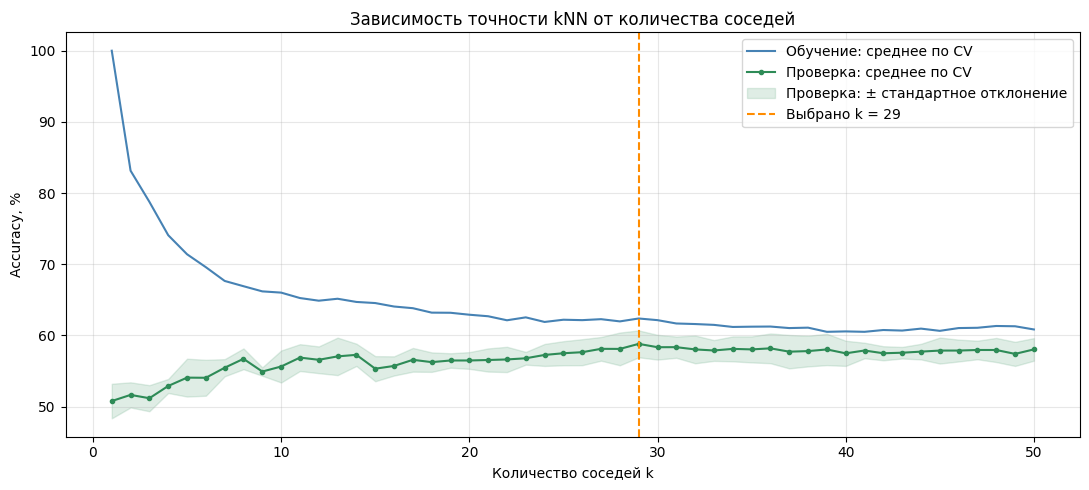

In [ ]:
plt.figure(figsize=(11, 5))

plt.plot(
    results["k"],
    results["train_accuracy"] * 100,
    label="Обучение: среднее по CV",
    color="steelblue"
)

plt.plot(
    results["k"],
    results["cv_accuracy"] * 100,
    marker="o",
    markersize=3,
    label="Проверка: среднее по CV",
    color="seagreen"
)

plt.fill_between(
    results["k"],
    (results["cv_accuracy"] - results["cv_std"]) * 100,
    (results["cv_accuracy"] + results["cv_std"]) * 100,
    color="seagreen",
    alpha=0.15,
    label="Проверка: ± стандартное отклонение"
)

plt.axvline(
    best_k,
    color="darkorange",
    linestyle="--",
    label=f"Выбрано k = {best_k}"
)

plt.xlabel("Количество соседей k")
plt.ylabel("Accuracy, %")
plt.title("Зависимость точности kNN от количества соседей")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Как рассчитываются метрики

**Accuracy** — доля полностью правильных предсказаний:

$$
Accuracy=\frac{\text{число правильных ответов}}{\text{число всех объектов}}.
$$

Для каждого класса отдельно определяются:

- TP — объекты этого класса, распознанные правильно;
- FP — объекты других классов, ошибочно отнесённые к этому;
- FN — объекты этого класса, ошибочно отнесённые к другим.

**Precision** — какая доля предсказаний этого класса правильная:

$$
Precision=\frac{TP}{TP+FP}.
$$

**Recall** — какую долю настоящих объектов класса удалось найти:

$$
Recall=\frac{TP}{TP+FN}.
$$

**F1** — гармоническое среднее precision и recall:

$$
F1=\frac{2\cdot Precision\cdot Recall}{Precision+Recall}.
$$


Параметр zero_division=0 задаёт вывод нуля для неопределённой метрики,
например precision класса, который модель ни разу не предсказала.

In [ ]:
# Проверяем выбранную модель на отдельном тесте.
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

# Сохраняем расчёты для последующего блока выводов.
balanced_acc = balanced_accuracy_score(y_test, y_pred)
macro_f1 = f1_score(
    y_test,
    y_pred,
    labels=classes,
    average="macro",
    zero_division=0
)
mae = mean_absolute_error(y_test, y_pred)

# Базовый вариант: всегда предсказывать самый частый класс.
majority_class = int(y_train.mode().iloc[0])
baseline_pred = np.full(len(y_test), majority_class)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

print(f"Accuracy: {accuracy:.2%}")
print(
    f"Accuracy постоянного прогноза "
    f"{majority_class}: {baseline_accuracy:.2%}"
)

print("\nОтчёт по классам:")
print(classification_report(
    y_test,
    y_pred,
    labels=classes,
    digits=3,
    zero_division=0
))

Accuracy: 56.43%
Accuracy постоянного прогноза 5: 42.63%

Отчёт по классам:
              precision    recall  f1-score   support

           3      0.000     0.000     0.000         2
           4      0.000     0.000     0.000        11
           5      0.620     0.757     0.682       136
           6      0.519     0.539     0.529       128
           7      0.400     0.205     0.271        39
           8      0.000     0.000     0.000         3

    accuracy                          0.564       319
   macro avg      0.257     0.250     0.247       319
weighted avg      0.522     0.564     0.536       319



## Матрица ошибок

Строки матрицы соответствуют настоящим оценкам, столбцы — предсказанным.

На главной диагонали находятся правильные ответы. Остальные ячейки
показывают ошибки: например, строка 5 и столбец 6 означают, что вино
с настоящей оценкой 5 получило прогноз 6.

Сумма главной диагонали, делённая на сумму всех элементов, равна accuracy.

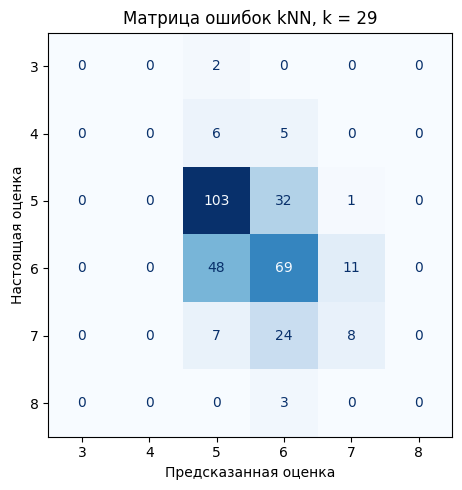

Accuracy по матрице: 180 / 319 = 56.43%


In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=classes)

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
).plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

ax.set_xlabel("Предсказанная оценка")
ax.set_ylabel("Настоящая оценка")
ax.set_title(f"Матрица ошибок kNN, k = {best_k}")

plt.tight_layout()
plt.show()

print(
    f"Accuracy по матрице: "
    f"{np.trace(cm)} / {cm.sum()} = {np.trace(cm) / cm.sum():.2%}"
)

## ROC-кривая и ROC-AUC

ROC-кривая показывает, как меняется соотношение правильно найденных объектов
и ложных срабатываний при изменении порога классификации.

Для выбранного класса модель выдаёт оценку вероятности принадлежности к нему.
Если эта оценка не меньше порога, считаем объект положительным.

При высоком пороге модель относит к классу меньше объектов.
При снижении порога обычно увеличивается и количество найденных объектов
нужного класса, и количество ложных срабатываний.

По горизонтальной оси располагается FPR — доля ложных срабатываний:

$$
FPR=\frac{FP}{FP+TN}.
$$

По вертикальной оси располагается TPR — доля правильно найденных объектов
положительного класса, то есть recall:

$$
TPR=\frac{TP}{TP+FN}.
$$

Здесь:

- TP — объекты выбранного класса, правильно отнесённые к нему;
- FN — объекты выбранного класса, которые модель пропустила;
- FP — объекты других классов, ошибочно отнесённые к выбранному;
- TN — объекты других классов, правильно отклонённые.

Каждый порог задаёт точку (FPR, TPR). Из этих точек строится ROC-кривая.
Желательны высокая TPR и низкая FPR, то есть положение ближе к левому
верхнему углу графика.

### Что означает AUC

AUC — площадь под ROC-кривой:

$$
AUC=\int_0^1 TPR(FPR)\,dFPR.
$$

Для построенной по данным кривой площадь вычисляется численно,
суммированием площадей трапеций.

- AUC = 1: идеальное разделение положительных и отрицательных объектов.
- AUC около 0,5: уровень случайного ранжирования.
- AUC меньше 0,5: порядок оценок в целом направлен противоположно правильному.

AUC характеризует ранжирование: насколько часто объект нужного класса
получает более высокую оценку принадлежности, чем объект другого класса.
Равенство оценок учитывается как половина правильно упорядоченной пары.

### Применение к качеству вина

Для каждой оценки качества строится отдельная ROC-кривая:

- оценка 3 против остальных;
- оценка 4 против остальных;
- и так далее.

Используем вероятности predict_proba(). При равном голосовании kNN
вероятность класса оценивается долей соседей этого класса среди k ближайших.

Дополнительно рассчитываем Macro ROC-AUC — среднее AUC всех классов:

$$
AUC_{macro}=\frac{1}{C}\sum_{c=1}^{C}AUC_c,
$$

где C — количество классов. Каждый класс имеет одинаковый вес.

ROC-AUC и accuracy измеряют разные свойства модели.
Например, AUC = 0,8 не означает 80% правильных предсказаний.

Для редких оценок качества тестовых объектов мало, поэтому их ROC-кривые
и AUC могут существенно меняться при другом разбиении данных.

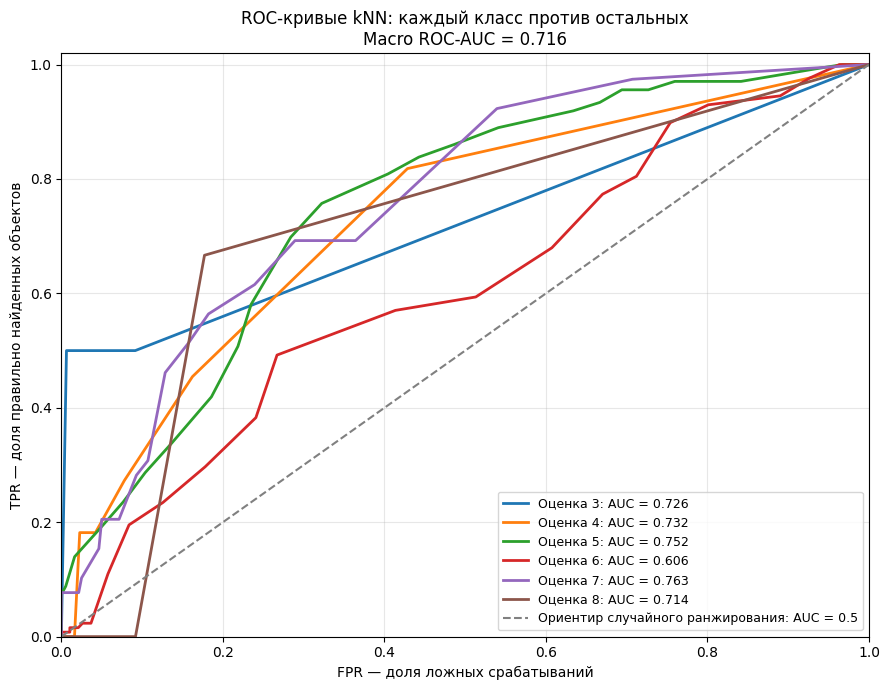

,Объектов класса в тесте,ROC-AUC
Оценка качества,,
3,2,0.726
4,11,0.732
5,136,0.752
6,128,0.606
7,39,0.763
8,3,0.714


Macro ROC-AUC (OvR): 0.7155


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, auc, roc_auc_score

# Вероятности каждого класса для объектов отдельной тестовой выборки.
# Pipeline самостоятельно применяет ранее обученный StandardScaler.
y_proba = best_model.predict_proba(X_test)

# Порядок классов соответствует столбцам y_proba.
roc_classes = np.asarray(best_model.classes_)
y_true_roc = np.asarray(y_test)

# Для полного многоклассового отчёта каждый класс должен быть в тесте.
if not np.array_equal(np.unique(y_true_roc), roc_classes):
    raise ValueError(
        "Для ROC-AUC по всем классам тестовая выборка должна "
        "содержать каждый класс обученной модели."
    )

auc_rows = []

fig, ax = plt.subplots(figsize=(9, 7))

for i, class_label in enumerate(roc_classes):
    # Выбранный класс = 1, все остальные классы = 0.
    y_binary = (y_true_roc == class_label).astype(int)

    # Вероятность принадлежности именно выбранному классу.
    class_probabilities = y_proba[:, i]

    fpr, tpr, thresholds = roc_curve(
        y_binary,
        class_probabilities
    )

    class_auc = auc(fpr, tpr)

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"Оценка {class_label}: AUC = {class_auc:.3f}"
    )

    auc_rows.append({
        "Оценка качества": class_label,
        "Объектов класса в тесте": int(y_binary.sum()),
        "ROC-AUC": class_auc
    })

# Среднее AUC всех классов с одинаковыми весами.
macro_auc = roc_auc_score(
    y_true_roc,
    y_proba,
    labels=roc_classes,
    multi_class="ovr",
    average="macro"
)

ax.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    label="Ориентир случайного ранжирования: AUC = 0.5"
)

ax.set_xlabel("FPR — доля ложных срабатываний")
ax.set_ylabel("TPR — доля правильно найденных объектов")
ax.set_title(
    f"ROC-кривые kNN: каждый класс против остальных\n"
    f"Macro ROC-AUC = {macro_auc:.3f}"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)
ax.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()

auc_table = pd.DataFrame(auc_rows).set_index("Оценка качества")
display(auc_table.round(3))

print(f"Macro ROC-AUC (OvR): {macro_auc:.4f}")